# Data cleaning and EDA

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
dataset=pd.read_csv('insurance.csv')

In [3]:
dataset.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
dataset.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [5]:
dataset.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [6]:
dataset.shape

(1338, 7)

In [7]:
print(f"Duplicate Row: {dataset.duplicated().sum()}")

Duplicate Row: 1


In [8]:
dataset[dataset.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [9]:
dataset=dataset.drop_duplicates().reset_index(drop=True)

In [10]:
print(f"Duplicate Row: {dataset.duplicated().sum()}")

Duplicate Row: 0


In [11]:
print("Mean:", dataset["charges"].mean())
print("Median:", dataset["charges"].median())
print("Skewness:", dataset["charges"].skew())

Mean: 13279.121486655948
Median: 9386.1613
Skewness: 1.5153909108403478


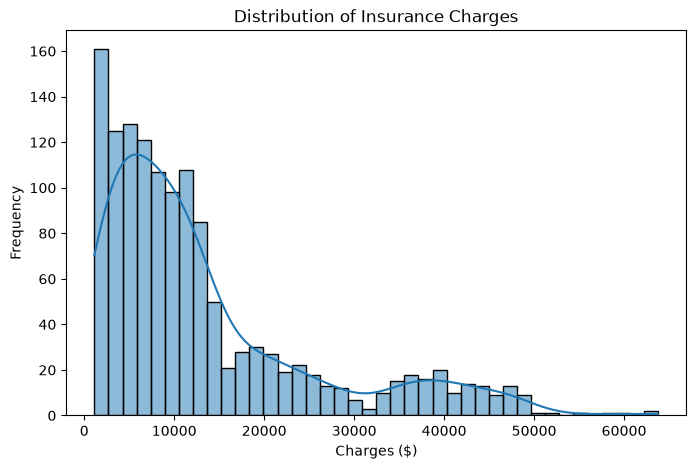

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(dataset["charges"], bins=40, kde=True)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Charges ($)")
plt.ylabel("Frequency")

plt.show()

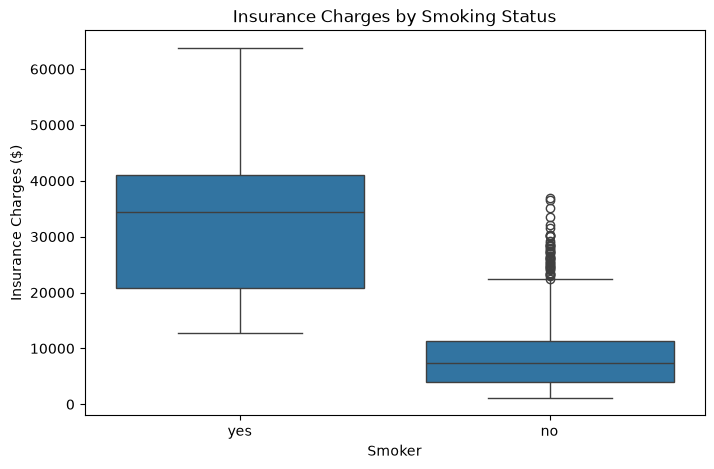

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=dataset,
    x='smoker',
    y='charges'
)
plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges ($)")

plt.show()


In [14]:
dataset.groupby('smoker')['charges'].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
smoker,,,,,
no,1063,8440.66,7345.73,1121.87,36910.61
yes,274,32050.23,34456.35,12829.46,63770.43


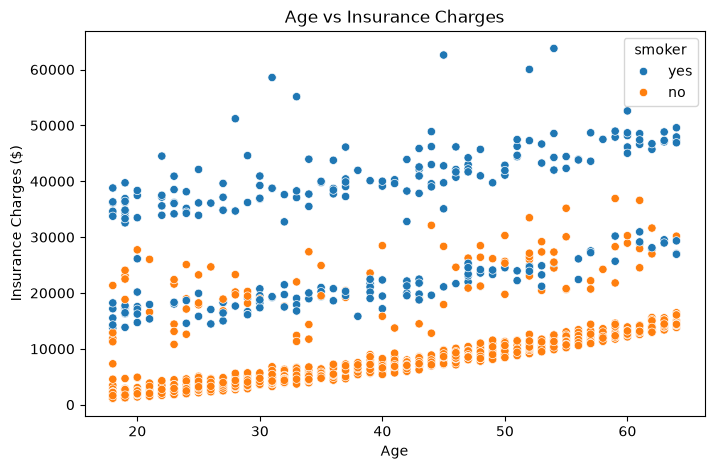

In [15]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=dataset,
    x='age',
    y='charges',
    hue="smoker",
    alpha=1.0
)
plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges ($)")

plt.show()

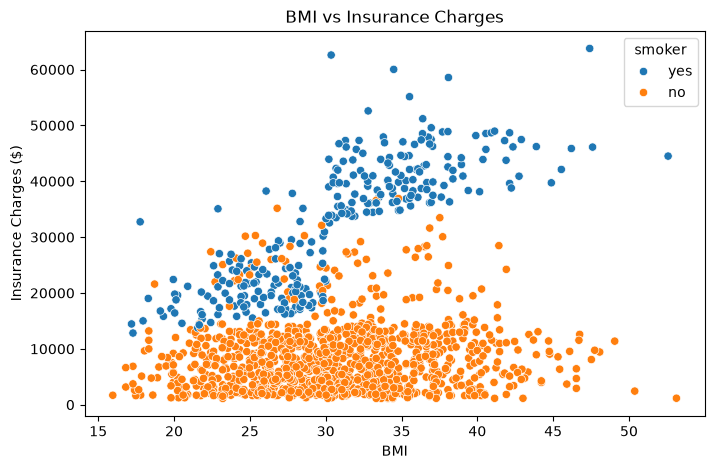

In [16]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=dataset,
    x='bmi',
    y='charges',
    hue='smoker'
)
plt.title("BMI vs Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges ($)")

plt.show()

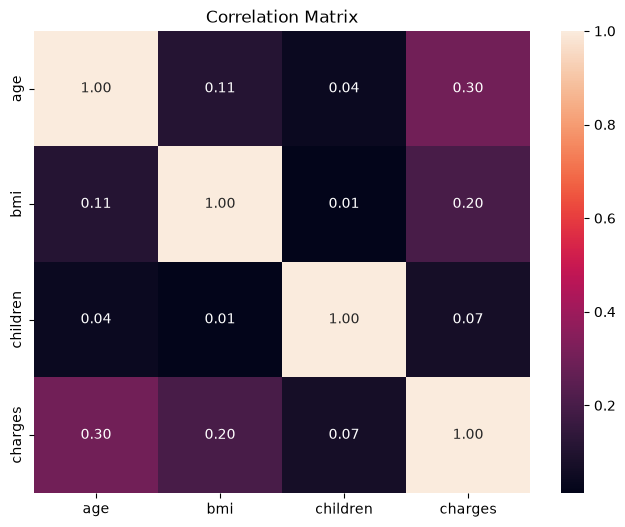

In [17]:
numeric_data=dataset.select_dtypes(include='number')
correlation_matrix = numeric_data.corr()

# Visualize correlations
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    # cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [18]:
print("Dataset shape:", dataset.shape)

print("\nMissing values:")
print(dataset.isnull().sum())

print("\nDuplicate rows:", dataset.duplicated().sum())

print("\nCharges skewness:", dataset["charges"].skew())

print("\nData types:")
print(dataset.dtypes)

Dataset shape: (1337, 7)

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 0

Charges skewness: 1.5153909108403478

Data types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


# Data Preprocessing

In [19]:
x=dataset.drop('charges',axis=1)
y=dataset['charges']

print("X dimensions:", x.ndim)
print("y dimensions:", y.ndim)

X dimensions: 2
y dimensions: 1


In [20]:
dataset.groupby("sex")["charges"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
sex,,,
female,662,12569.58,9412.96
male,675,13975.00,9377.90


In [21]:

# Identify columns from X only
numerical_features = x.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = x.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)


Numerical features: ['age', 'bmi', 'children']
Categorical features: ['sex', 'smoker', 'region']


## Preprocessing Pipeline

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline

In [23]:
numerical_transformer=StandardScaler()

categorical_transformer=OneHotEncoder(handle_unknown='ignore')

preprocessor=ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor

In [25]:
models={
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

In [26]:
print("Model Prepare:")
for i in models:
    print(i)

Model Prepare:
Linear Regression
Random Forest
Gradient Boosting


## Connecting Pipeline

In [27]:
pipeline={}

for name,models in models.items():
    pipeline[name]=Pipeline(
        steps=[
            ("Preprocessor",preprocessor),
            ("model",models)
        ]
    )
print("Pipelines created:")
print(list(pipeline.keys()))


Pipelines created:
['Linear Regression', 'Random Forest', 'Gradient Boosting']


## Cross validation

In [ ]:
from sklearn.model_selection import KFold,cross_validate

cv=KFold(n_splits=5,shuffle=True,random_state=42)
scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2"
}


results = []

for name, model_pipeline in pipeline.items():

    print("Evaluating:", name)

    scores = cross_validate(
        model_pipeline,
        x,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": (-scores["test_mse"].mean()) ** 0.5,
        "R2": scores["test_r2"].mean()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

results_df.round(3)



Evaluating: Linear Regression
Evaluating: Random Forest
Evaluating: Gradient Boosting


,Model,MAE,RMSE,R2
2,Gradient Boosting,2512.719,4585.042,0.853
1,Random Forest,2667.400,4848.320,0.837
0,Linear Regression,4209.910,6108.492,0.739


In [33]:
print("Number of results:", len(results_df))
print("Results:", results_df)

Number of results: 3
Results:                Model          MAE         RMSE        R2
2  Gradient Boosting  2512.718613  4585.042299  0.853460
1      Random Forest  2667.400021  4848.319703  0.836554
0  Linear Regression  4209.909976  6108.491654  0.739027


## Dividing into train and test split

In [34]:
from sklearn.model_selection import train_test_split

xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.20,random_state=42)


print("Training features:", xtrain.shape)
print("Testing features:", xtest.shape)

print("Training target:", ytrain.shape)
print("Testing target:", ytest.shape)

Training features: (1069, 6)
Testing features: (268, 6)
Training target: (1069,)
Testing target: (268,)


## model training

In [35]:
train_model={}

for name,model_pipeline in pipeline.items():
    print("Training",name)
    model_pipeline.fit(xtrain,ytrain)
    train_model[name] = model_pipeline

print("\nAll models trained successfully!")


Training Linear Regression
Training Random Forest
Training Gradient Boosting

All models trained successfully!


In [36]:

predictions = {}

for name, model in train_model.items():

    y_pred = model.predict(xtest)

    predictions[name] = y_pred

    print(f"{name} predictions completed!")

print("\nAll predictions completed!")


Linear Regression predictions completed!
Random Forest predictions completed!
Gradient Boosting predictions completed!

All predictions completed!


In [37]:
y_pred = model.predict(xtest)

In [39]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


evaluation_results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(ytest, y_pred)

    rmse = np.sqrt(mean_squared_error(ytest, y_pred))

    r2 = r2_score(ytest, y_pred)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    by="RMSE"
).round(2)

evaluation_df


,Model,MAE,RMSE,R2 Score
2,Gradient Boosting,2535.06,4271.89,0.90
1,Random Forest,2560.21,4638.18,0.88
0,Linear Regression,4177.05,5956.34,0.81


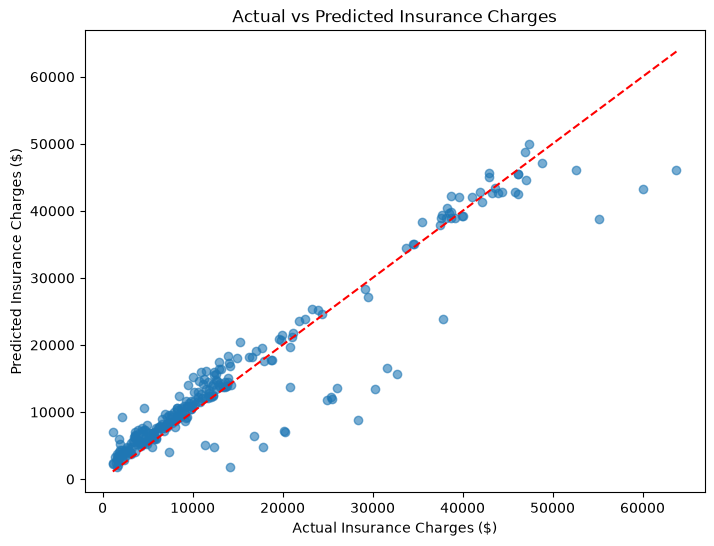

In [ ]:

best_model = train_model["Gradient Boosting"]

y_pred = predictions["Gradient Boosting"]

plt.figure(figsize=(8, 6))

plt.scatter(ytest, y_pred, alpha=0.6)

plt.plot(
    [ytest.min(), ytest.max()],
    [ytest.min(), ytest.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Insurance Charges ($)")
plt.ylabel("Predicted Insurance Charges ($)")
plt.title("Actual vs Predicted Insurance Charges")

plt.show()


## Residual analysis

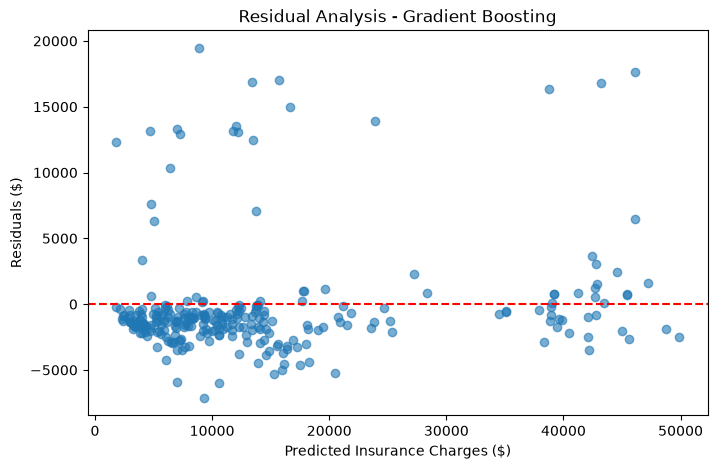

In [41]:

residuals = ytest - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Insurance Charges ($)")
plt.ylabel("Residuals ($)")
plt.title("Residual Analysis - Gradient Boosting")

plt.show()


## Feature Importance

                  Feature  Importance
5          cat__smoker_no    0.351288
6         cat__smoker_yes    0.319807
1                num__bmi    0.188087
0                num__age    0.122479
2           num__children    0.013737
7   cat__region_northeast    0.001765
10  cat__region_southwest    0.000702
3         cat__sex_female    0.000700
8   cat__region_northwest    0.000684
4           cat__sex_male    0.000482
9   cat__region_southeast    0.000270


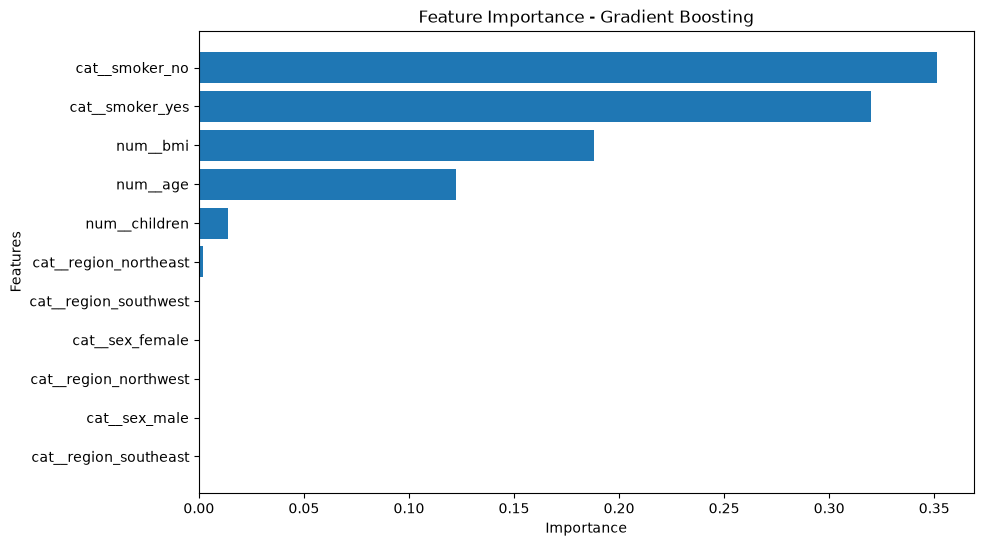

In [42]:


# Get the trained Gradient Boosting model
gb_model = best_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    best_model.named_steps["Preprocessor"]
    .get_feature_names_out()
)

# Get feature importance
importance = gb_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

# Visualize
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Feature Importance - Gradient Boosting")

plt.gca().invert_yaxis()

plt.show()


In [43]:
import joblib

joblib.dump(best_model, "insurance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [44]:
import joblib
import pandas as pd

loaded_model = joblib.load("insurance_model.pkl")

new_customer = pd.DataFrame([{
    "age": 25,
    "sex": "male",
    "bmi": 24.5,
    "children": 0,
    "smoker": "no",
    "region": "southwest"
}])

prediction = loaded_model.predict(new_customer)

print("Predicted Insurance Charges: $", round(prediction[0], 2))

Predicted Insurance Charges: $ 3610.54
